# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Include contributors names here!**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [12]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn 

In [13]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

*This section should include a brief introduction to the task and the data (assume this is a report you are delivering to a professional body (e.g. Scottish Government)).*

*State which supervised learning question you are answering.*

*Briefly outline the approaches being used (for both the clustering and your chosen supervised learning task) and the conclusions that you are able to draw.*

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

2. Exploratory Data Analysis and Feature Engineering

Exploratory data analysis (EDA) was carried out to understand the structure, quality and characteristics of the river water-level data before modelling. The analysis focuses on data availability, unusual measurements, temporal patterns and relationships between water-level variables. These findings are used to guide feature selection and preprocessing for the clustering and regression tasks.

2.1 Data overview

The four datasets were first examined to understand their structure, including the number of monitoring records, variables and data types.

In [29]:
# 3.1 Data Overview
# Check the dimensions of the four datasets
print("Average water levels:", df_avg.shape)
print("Minimum water levels:", df_min.shape)
print("Maximum water levels:", df_max.shape)
print("Monitoring locations:", df_locs.shape)
# Examine the structure of the average water-level dataset
df_avg.info()
# Check the time period
print("First date:", df_avg.columns[3])
print("Last date:", df_avg.columns[-1])

Average water levels: (392, 4382)
Minimum water levels: (392, 4382)
Maximum water levels: (392, 4382)
Monitoring locations: (392, 5)
<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), str(3)
memory usage: 13.1 MB
First date: 05/10/2014
Last date: 08/10/2026


Four datasets were provided, containing daily average, minimum and maximum river water levels, together with geographical information about monitoring locations in Scotland. The three water-level datasets each contain 392 monitoring records and 4,382 columns. The first three columns contain County, Station_Name and Observation_ID, while the remaining 4,379 columns contain daily water-level measurements from 5 October 2014 to 8 October 2026. The location dataset contains the same 392 observation IDs, along with latitude and longitude. Some monitoring stations have more than one observation record, so Observation_ID was used to identify individual records throughout the analysis.

2.2 Data Quality Assessment and Preprocessing Decisions

Data quality was assessed to identify potential issues that could affect subsequent modelling. The analysis focuses on missing values, data availability across monitoring records and dates, and consistency between the datasets.

2.2.1  Missing Values and Data Coverage

Missing values were examined to understand data completeness and differences in data availability between monitoring records and over time. This is important because missing observations may affect feature calculations and model reliability.

In [32]:
# Count missing values in each dataset
print("Average:", df_avg.isna().sum().sum())
print("Minimum:", df_min.isna().sum().sum())
print("Maximum:", df_max.isna().sum().sum())
# Compare missing-value patterns
print("Average vs Minimum:",
      df_avg.isna().equals(df_min.isna()))
print("Average vs Maximum:",
      df_avg.isna().equals(df_max.isna()))
# Calculate the missing percentage
missing_percentage = (
    df_avg.iloc[:, 3:].isna().sum().sum()
    / df_avg.iloc[:, 3:].size * 100
)
print("Missing percentage:", round(missing_percentage, 1))

Average: 525877
Minimum: 525877
Maximum: 525877
Average vs Minimum: True
Average vs Maximum: True
Missing percentage: 30.6


The results show that all three water-level datasets contain 525,877 missing values, accounting for approximately 30.6% of the measurements. Further checks show that the missing values occur at exactly the same positions across all three datasets. This suggests that some monitoring stations have no recorded minimum, average or maximum water levels on certain days.

2.2.2 Missing Values by Monitoring Station

To further investigate missing data, the number of available observations was calculated for each monitoring record. This helps identify which monitoring records have relatively complete data and which have substantial gaps. Data completeness is important for both clustering and regression, as missing observations may affect feature calculations and model training.

In [37]:
# Count missing values for each monitoring record
missing_records = df_avg.iloc[:, 3:].isna().sum(axis=1)
# Calculate valid observations
valid_records = 4379 - missing_records
# Create a table showing data availability
station_coverage = df_avg[["Station_Name", "Observation_ID"]].copy()
station_coverage["Valid_Records"] = valid_records
station_coverage["Missing_Records"] = missing_records
# Display the most complete records
print("Most complete monitoring records:")
display(station_coverage[["Station_Name", "Valid_Records", "Missing_Records"]]
        .sort_values("Valid_Records", ascending=False).head(10))
# Display the least complete records
print("Least complete monitoring records:")
display(station_coverage[["Station_Name", "Valid_Records", "Missing_Records"]]
        .sort_values("Valid_Records").head(10))

Most complete monitoring records:


,Station_Name,Valid_Records,Missing_Records
301,"River Tweed, Sprouston",4373,6
122,"River Esk, Canonbie (SEPA Site)",4331,48
348,Kinlochbervie,3376,1003
43,Tobermory,3376,1003
44,Tobermory,3376,1003
41,Portrush,3376,1003
349,Kinlochbervie,3376,1003
86,Wick,3376,1003
40,Portrush,3376,1003
388,Portpatrick,3376,1003


Least complete monitoring records:


,Station_Name,Valid_Records,Missing_Records
20,"Elliot Water, Kelly Den - Arbilot",452,3927
189,"Carron, Carron upstream (Stonehaven)",480,3899
285,"Newhall Burn, Newhall Bridge",570,3809
383,"Dargall Lane, Dargall Lane",572,3807
25,"Lunan Water, Murton",647,3732
57,"Irvine, Glenfield",661,3718
166,"Loch Oich, Bridge of Oich",1062,3317
190,"Carron, Cleuchhead",1063,3316
164,"Loch Flemington, Loch Flemington",1110,3269
334,"Loch Ard Burn, Duchray",1212,3167


The results show that data availability varies considerably between monitoring records. River Tweed at Sprouston has the most complete record, with 4,373 valid observations and only 6 missing values, followed by River Esk at Canonbie (SEPA Site), with 4,331 valid observations and 48 missing values. In contrast, Elliot Water at Kelly Den–Arbilot has the fewest valid observations (452), followed by Carron upstream (480), Newhall Burn (570), Dargall Lane (572) and Lunan Water (647). These monitoring records have more than 3,700 missing observations each. This difference in data completeness needs to be considered during preprocessing, as records with limited observations may affect feature calculations and the reliability of clustering and regression models.

2.2.3  Data Coverage Over Time

In addition to differences between monitoring records, data availability was examined over time to identify periods with limited observations. This is important for understanding the historical coverage of the datasets and the potential impact of missing data on model development.

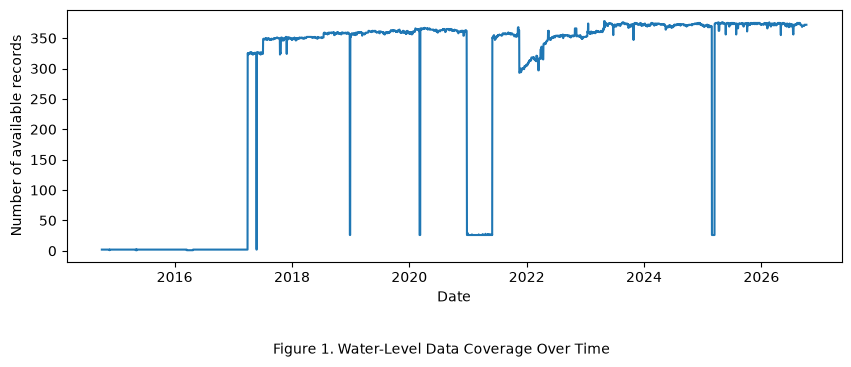

In [40]:
# Count available records for each date
daily_coverage = 392 - df_avg.iloc[:, 3:].isna().sum()
# Convert date labels to datetime
dates = pd.to_datetime(daily_coverage.index, dayfirst=True)
# Plot data coverage over time
plt.figure(figsize=(10, 4))
plt.plot(dates, daily_coverage.values)
plt.xlabel("Date")
plt.ylabel("Number of available records")
# Leave space for the figure caption
plt.subplots_adjust(bottom=0.25)
# Add figure caption below the plot
plt.figtext(0.5, 0.02,
            "Figure 1. Water-Level Data Coverage Over Time",
            ha="center")
plt.show()

The three water-level datasets each contain 525,877 missing measurements, representing approximately 30.6% of the daily observations. The missing values occur at the same positions across all three datasets.
Data availability varied considerably between monitoring records. River Tweed at Sprouston had the most complete record, with 4,373 valid observations, while Elliot Water at Kelly Den–Arbilot had only 452.

Figure 1 shows that data coverage changed considerably over time. Between 2014 and early 2017, only around 1–2 monitoring records were available per day. Coverage then increased sharply in 2017 and graduall reached around 370 records in later years. However, several sudden drops in data availability can still be observed.

These differences need to be considered during feature engineering and model development, as incomplete historical records may affect the reliability of the calculated features and the analysis of long-term water-level patterns.

2.2.4 Data Consistency and Duplicate Records

After examining missing values and data coverage, the four datasets were checked for duplicate observation IDs and data consistency. This was important to ensure that the average, minimum and maximum water-level measurements could be correctly matched by monitoring record and date during feature engineering and modelling.

In [41]:
# Check duplicated observation IDs
print("Average:", df_avg["Observation_ID"].duplicated().sum())
print("Minimum:", df_min["Observation_ID"].duplicated().sum())
print("Maximum:", df_max["Observation_ID"].duplicated().sum())
print("Locations:", df_locs["Observation_ID"].duplicated().sum())
# Check observation ID consistency
print("Average vs Minimum:",
      df_avg["Observation_ID"].equals(df_min["Observation_ID"]))
print("Average vs Maximum:",
      df_avg["Observation_ID"].equals(df_max["Observation_ID"]))
# Compare observation IDs with the location dataset
avg_ids = df_avg["Observation_ID"].sort_values().reset_index(drop=True)
loc_ids = df_locs["Observation_ID"].sort_values().reset_index(drop=True)
print("Same location IDs:", avg_ids.equals(loc_ids))
# Check date-column consistency
print("Average vs Minimum dates:",
      df_avg.columns[3:].equals(df_min.columns[3:]))
print("Average vs Maximum dates:",
      df_avg.columns[3:].equals(df_max.columns[3:]))

Average: 0
Minimum: 0
Maximum: 0
Locations: 0
Average vs Minimum: True
Average vs Maximum: True
Same location IDs: True
Average vs Minimum dates: True
Average vs Maximum dates: True


No duplicated observation IDs were found in the four datasets. The average, minimum and maximum water-level datasets contain the same observation IDs and dates in the same order.
The location dataset contains the same observation IDs but in a different row order. Therefore, Observation_ID will be used to match records when combining geographical information with water-level measurements.
These results confirm that the minimum, average and maximum water-level measurements can be matched correctly by monitoring record and date.

2.3 Data Splitting for Regression

For the regression task, the water-level datasets were split based on time to prevent data leakage, as the aim is to predict future water levels using historical observations.
The training set covers 5 October 2014 to 31 August 2025, while the validation set covers 1 September 2025 to 31 August 2026. A full 12-month period was selected for validation to include all four seasons, allowing the models to be evaluated under different seasonal water-level conditions. The validation set is used for model tuning and comparison.
The test set covers 1 September 2026 to 8 October 2026 and is used to compare predictions with available observations. Although the project aims to predict water levels from September to November 2026, the datasets only contain observations up to 8 October 2026. Therefore, only part of the prediction period can be evaluated.
The same time periods were used for the average, minimum and maximum water-level datasets.

In [30]:
# Split average water-level data
avg_train = df_avg.loc[:, "05/10/2014":"31/08/2025"]
avg_val = df_avg.loc[:, "01/09/2025":"31/08/2026"]
avg_test = df_avg.loc[:, "01/09/2026":"08/10/2026"]
# Split minimum water-level data
min_train = df_min.loc[:, "05/10/2014":"31/08/2025"]
min_val = df_min.loc[:, "01/09/2025":"31/08/2026"]
min_test = df_min.loc[:, "01/09/2026":"08/10/2026"]
# Split maximum water-level data
max_train = df_max.loc[:, "05/10/2014":"31/08/2025"]
max_val = df_max.loc[:, "01/09/2025":"31/08/2026"]
max_test = df_max.loc[:, "01/09/2026":"08/10/2026"]
# Check the number of observations in each split
print("Training:", avg_train.shape)
print("Validation:", avg_val.shape)
print("Test:", avg_test.shape)

Training: (392, 3976)
Validation: (392, 365)
Test: (392, 38)


The results confirm that the three water-level datasets were successfully divided into training, validation and test sets. Each set retains all 392 monitoring records, with 3,976 date columns for training, 365 for validation and 38 for testing. The same date ranges were applied to the average, minimum and maximum water-level datasets to maintain consistency across the three measurements.

2.4 Outlier Investigation

The descriptive statistics and histograms revealed several extreme water-level values that may be affecting the results. To investigate these observations, measurements above 100 or below −100 were identified in the training data. These thresholds were chosen as preliminary screening limits to highlight particularly extreme values, rather than as scientifically established outlier boundaries. The flagged observations will be investigated further before deciding whether any data cleaning is necessary.

The water-level datasets were examined for unusually large positive and negative measurements. These values may represent data quality issues and could affect the descriptive statistics and machine learning models. Measurements above 100 or below −100 were identified for further investigation using preliminary screening thresholds.

In [45]:
# Select all average water-level measurements
avg_all = df_avg.iloc[:, 3:]
# Count extreme measurements
high_values = (avg_all > 100).sum().sum()
low_values = (avg_all < -100).sum().sum()
print("Measurements above 100:", high_values)
print("Measurements below -100:", low_values)
print("Total extreme measurements:", high_values + low_values)
# Count extreme measurements for each monitoring record
extreme_counts = ((avg_all > 100) | (avg_all < -100)).sum(axis=1)
# Create a table of monitoring records
extreme_stations = df_avg[["Station_Name", "Observation_ID"]].copy()
extreme_stations["Extreme_Values"] = extreme_counts
# Display the five most affected records
display(extreme_stations.sort_values(
    "Extreme_Values", ascending=False).head(5))
# Count records containing extreme measurements
print("Records with extreme values:", (extreme_counts > 0).sum())

Measurements above 100: 49
Measurements below -100: 29
Total extreme measurements: 78


,Station_Name,Observation_ID,Extreme_Values
182,"Spey, Spey Dam",inverness__spey-spey-dam__obs1,26
329,"Endrick Water, Graystone Bridge",stirling-and-falkirk__endrick-water-graystone-...,10
45,"Annick Water, Chapeltoun Gauging Station",ayrshire-and-arran__annick-water__obs1,8
245,"Leven (Fife), Loch Leven Sluices",perth-and-kinross__leven-fife-loch-leven-sluic...,6
55,"Garnock, Kilbirnie",ayrshire-and-arran__garnock-kilbirnie__obs1,4


Records with extreme values: 20


In [47]:
# Find the highest and lowest values for each monitoring record
record_extremes = df_avg[["Station_Name"]].copy()
record_extremes["Highest_Level"] = avg_all.max(axis=1)
record_extremes["Lowest_Level"] = avg_all.min(axis=1)
# Display records with the highest measurements
print("Highest water-level measurements:")
display(record_extremes[["Station_Name", "Highest_Level"]]
        .sort_values("Highest_Level", ascending=False).head(5))
# Display records with the lowest measurements
print("Lowest water-level measurements:")
display(record_extremes[["Station_Name", "Lowest_Level"]]
        .sort_values("Lowest_Level").head(5))

Highest water-level measurements:


,Station_Name,Highest_Level
268,"Abhainn Bruachaig, Kinlochewe Lodge",999999.999
329,"Endrick Water, Graystone Bridge",307692.995
61,"Kilmarnock Water, Howard Park",170213.366
55,"Garnock, Kilbirnie",157895.392
245,"Leven (Fife), Loch Leven Sluices",118645.205


Lowest water-level measurements:


,Station_Name,Lowest_Level
379,"Blackwater of Dee, Loch Dee Outlet",-190475.436
182,"Spey, Spey Dam",-119562.593
170,"Lochy (Lochaber), Gairlochy",-76895.519
35,"Carradale Water, Dippen",-29.639
39,"Orchy, Glen Orchy",-29.250


In [48]:
# Select all daily minimum and maximum measurements
min_all = df_min.iloc[:, 3:]
max_all = df_max.iloc[:, 3:]
# Check water-level consistency
print("Minimum > Average:",
      (min_all > avg_all).sum().sum())
print("Average > Maximum:",
      (avg_all > max_all).sum().sum())

Minimum > Average: 0
Average > Maximum: 0


The initial screening identified 78 extreme measurements across the complete average water-level dataset, including 49 values above 100 and 29 values below −100. These measurements were found across 20 monitoring records, with most concentrated in a small number of records. Spey Dam contained the highest number of extreme measurements (26), followed by Endrick Water at Graystone Bridge (10).

Further investigation identified unusually large positive and negative measurements. Kinlochewe Lodge recorded the highest value of 999999.999, while Blackwater of Dee at Loch Dee Outlet recorded the lowest value of −190475.436. These extreme measurements may represent data errors and could strongly influence the descriptive statistics and machine learning models.

The consistency checks found no cases where the minimum water level exceeded the average or where the average exceeded the maximum. However, this does not confirm that all measurements are accurate.

Values outside the range of −100 to 100 were flagged as potentially unreliable. This threshold was used for preliminary screening rather than as a scientifically established limit. For clustering, these values will be treated as missing during feature engineering, and the effect of this decision will be examined through sensitivity analysis.
for regression：：：：：







2.5 Exploratory Analysis of Water Levels

2.5.1 Water-Level Distributions and Variability

Descriptive statistics were calculated using the complete average water-level dataset to understand how water levels vary between monitoring records. The analysis focused on the mean and standard deviation of average water levels for each record.

The mean describes the average water level, while the standard deviation measures how much water levels vary over time. These statistics help identify differences between monitoring records and assess the influence of extreme measurements.

In [49]:
# Calculate mean water level for each monitoring record
station_mean = avg_all.mean(axis=1)
# Calculate standard deviation for each monitoring record
station_std = avg_all.std(axis=1)
# Summarise the results
print("Mean water-level statistics:")
print(station_mean.describe())
print("Water-level standard deviation statistics:")
print(station_std.describe())

Mean water-level statistics:
count    392.000000
mean       4.581932
std       42.471968
min     -195.774521
25%        0.358981
50%        0.507488
75%        0.758967
max      643.502457
dtype: float64
Water-level standard deviation statistics:
count      392.000000
mean       165.717914
std       1258.339544
min          0.036390
25%          0.164379
50%          0.232741
75%          0.331480
max      19706.577031
dtype: float64


The descriptive statistics show considerable differences between monitoring records. The median of the station-level mean water levels was approximately 0.507, while the mean was much higher at 4.582. Similarly, the median station-level standard deviation was only 0.233, compared with a mean of 165.718.
These large differences suggest that a small number of extreme measurements may be strongly influencing the results. This is consistent with the unusual values identified in Section 3.3.3 and highlights the importance of considering more robust measures of water-level variability during feature engineering.

2.5.2 Data Visualisation

To further investigate the differences observed in the descriptive statistics, histograms were used to examine the distributions of station-level mean water levels and standard deviations. These plots help identify where most monitoring records are concentrated and whether extreme values are present.

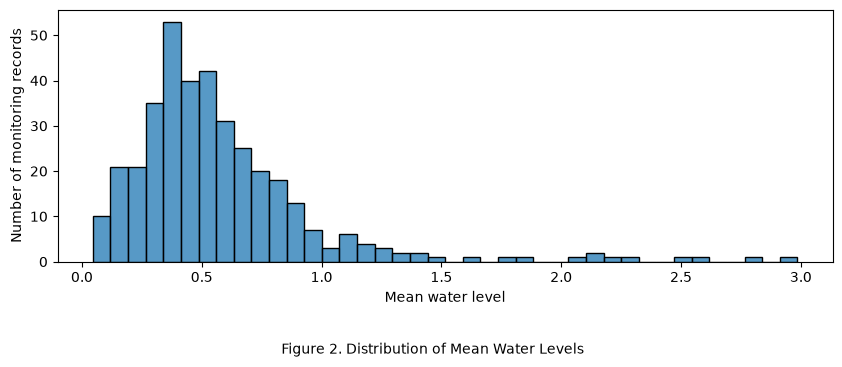

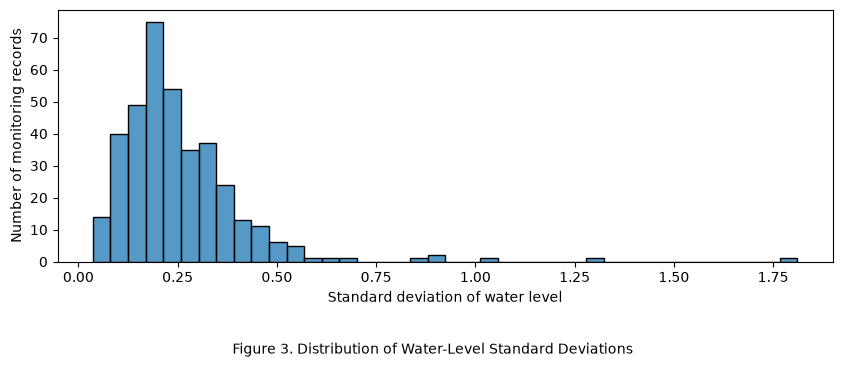

In [50]:
# Distribution of station-level mean water levels
plt.figure(figsize=(10, 4))
sns.histplot(
    station_mean[(station_mean >= -1) & (station_mean <= 3)],
    bins=40
)
plt.xlabel("Mean water level")
plt.ylabel("Number of monitoring records")
plt.subplots_adjust(bottom=0.25)
plt.figtext(0.5, 0.02,
            "Figure 2. Distribution of Mean Water Levels",
            ha="center")
plt.show()
# Distribution of station-level standard deviations
plt.figure(figsize=(10, 4))
sns.histplot(
    station_std[(station_std >= 0) & (station_std <= 2)],
    bins=40
)
plt.xlabel("Standard deviation of water level")
plt.ylabel("Number of monitoring records")
plt.subplots_adjust(bottom=0.25)
plt.figtext(0.5, 0.02,
            "Figure 3. Distribution of Water-Level Standard Deviations",
            ha="center")
plt.show()

The descriptive statistics show considerable differences between monitoring records. The median of the station-level mean water levels was approximately 0.507, while the mean was much higher at 4.582. Similarly, the median station-level standard deviation was only 0.233, compared with a mean of 165.718. These large differences suggest that extreme measurements may be strongly influencing the results.
Figures 2 and 3 show that both distributions are right-skewed. Most monitoring records have mean water levels between approximately 0.2 and 0.8, while their standard deviations are mainly concentrated between 0.1 and 0.4. However, some records have higher values, indicating differences in typical water levels and variability.
The histograms focus on the main distributions, excluding values outside the displayed ranges. The extreme measurements identified earlier may affect the mean and standard deviation. Therefore, more robust measures of water-level variability will be considered during feature engineering.



2.5.3 Temporal and Seasonal Patterns

This section examines how river water levels change across different months of the year. The aim is to identify seasonal patterns that may provide useful information for clustering and regression.
River Tweed at Sprouston was selected as an example because it has one of the most complete monitoring records. Its monthly water-level patterns were examined using the complete historical dataset.

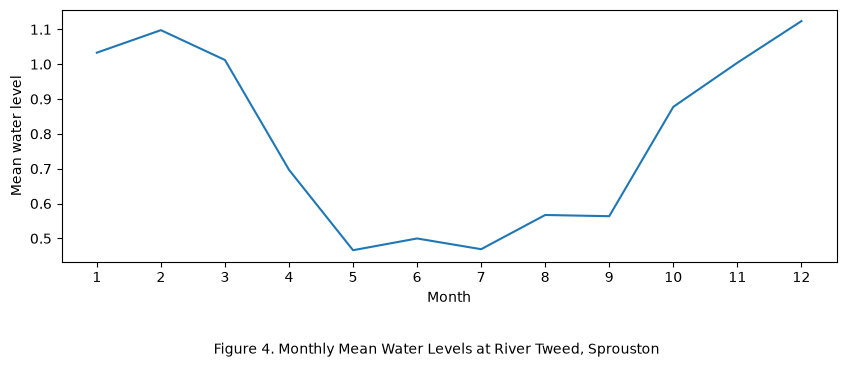

In [51]:
# Select water-level data for Tweed, Sprouston
sprouston = avg_all.loc[308]
# Convert dates into datetime
dates = pd.to_datetime(avg_all.columns, dayfirst=True)
# Create a DataFrame with month and water level
monthly_levels = pd.DataFrame({
    "Month": dates.month,
    "Water_Level": sprouston.values
})
# Calculate mean water level for each month
monthly_mean = monthly_levels.groupby("Month")["Water_Level"].mean()
# Plot monthly mean water levels
plt.figure(figsize=(10, 4))
plt.plot(monthly_mean.index, monthly_mean.values)
plt.xlabel("Month")
plt.ylabel("Mean water level")
plt.xticks(range(1, 13))
# Leave space for the figure caption
plt.subplots_adjust(bottom=0.25)
plt.figtext(0.5, 0.02,
            "Figure 4. Monthly Mean Water Levels at River Tweed, Sprouston",
            ha="center")
plt.show()

Figure 4 shows a clear seasonal pattern in average water levels at River Tweed, Sprouston. Water levels are generally higher during winter, reaching approximately 1.1 in December and February, and lower during late spring and summer, with the lowest levels around 0.47 in May and July. Water levels then increase again during autumn.
These findings suggest that seasonal information may be useful for clustering monitoring records with different water-level patterns and for predicting future water levels. However, this analysis is based on one monitoring record, and seasonal patterns may differ across other locations.

2.5.5  Relationships Between Minimum, Average and Maximum Water Levels

The relationships between daily minimum, average and maximum water levels were examined using correlation analysis. This helps us understand whether the three measurements contain similar information and how they are related.
River Tweed at Sprouston was used as an example because it has one of the most complete monitoring records. The analysis was carried out using the complete historical dataset.

In [52]:
# Compare water-level measurements at Tweed, Sprouston
water_level_comparison = pd.DataFrame({
    "Minimum": min_all.loc[308].values,
    "Average": avg_all.loc[308].values,
    "Maximum": max_all.loc[308].values
})
# Calculate the correlation matrix
display(water_level_comparison.corr())

,Minimum,Average,Maximum
Minimum,1.000000,0.947924,0.884255
Average,0.947924,1.000000,0.970836
Maximum,0.884255,0.970836,1.000000


The correlation analysis shows strong positive relationships between minimum, average and maximum water levels at River Tweed, Sprouston. The strongest correlation was between average and maximum water levels (r = 0.971), followed by minimum and average levels (r = 0.948) and minimum and maximum levels (r = 0.884).
These results suggest that the three measurements contain closely related information and generally change together. This may be useful when selecting features for modelling, although the relationships are based on one monitoring record and may differ across other locations.

2.6 Feature Engineering and Preprocessing Decisions

2.6.1 Feature Engineering for Clustering

2.6.1.1 Feature Selection

To group monitoring records based on their historical water-level behaviour, four features were selected: Interquartile Range (IQR), Median Absolute Daily Change, Winter–Summer Median Difference and Median Within-Day Range. These features were chosen to describe different aspects of water-level variation rather than focusing only on average water-level height.
Interquartile Range (IQR) measures the difference between the 75th and 25th percentiles of daily average water levels. It describes the spread of the middle 50% of observations and is less affected by extreme values than the standard deviation.
Median Absolute Daily Change measures the typical absolute difference in average water levels between consecutive days. This helps identify monitoring records where water levels change more rapidly.
Winter–Summer Median Difference measures the difference between median water levels in winter (December–February) and summer (June–August). A positive value indicates higher typical water levels in winter, while a negative value indicates higher levels in summer.
Median Within-Day Range measures the median difference between daily maximum and minimum water levels. This provides information about variation within a day that may not be captured by daily average measurements.
Together, these four features describe overall variability, daily changes, seasonal differences and within-day variation.

2.6.1.2 Data Preparation

Before calculating the clustering features, measurements outside the preliminary range of −100 to 100 were treated as missing values. The same screening rule was applied to the average, minimum and maximum water-level datasets.
The original datasets were kept unchanged. Features were then calculated using the available observations for each monitoring record, without removing entire records because of individual missing measurements.

In [54]:
# Create copies of the water-level measurements
avg_clean = avg_all.copy()
min_clean = min_all.copy()
max_clean = max_all.copy()
# Treat extreme measurements as missing
avg_clean[(avg_clean > 100) | (avg_clean < -100)] = np.nan
min_clean[(min_clean > 100) | (min_clean < -100)] = np.nan
max_clean[(max_clean > 100) | (max_clean < -100)] = np.nan

2.6.1.3 Clustering Features Engineering

In [56]:
# Feature 1: Interquartile Range (IQR)
iqr = (
    avg_clean.quantile(0.75, axis=1)
    - avg_clean.quantile(0.25, axis=1)
)
# Convert column names to dates
dates = pd.to_datetime(avg_clean.columns, dayfirst=True)
# Feature 2: Median Absolute Daily Change
daily_change = avg_clean.diff(axis=1).abs()
# Only compare consecutive calendar days
consecutive_days = (
    dates[1:] - dates[:-1]
) == pd.Timedelta(days=1)
daily_change = daily_change.iloc[:, 1:].loc[:, consecutive_days]
median_daily_change = daily_change.median(axis=1)
# Feature 3: Winter-Summer Median Difference
winter = dates.month.isin([12, 1, 2])
summer = dates.month.isin([6, 7, 8])
winter_median = avg_clean.loc[:, winter].median(axis=1)
summer_median = avg_clean.loc[:, summer].median(axis=1)
seasonal_difference = winter_median - summer_median
# Feature 4: Median Within-Day Range
within_day_range = max_clean - min_clean
median_within_day_range = within_day_range.median(axis=1)
# Combine the four features into one DataFrame
clustering_features = pd.DataFrame({
    "IQR": iqr,
    "Daily_Change": median_daily_change,
    "Seasonal_Difference": seasonal_difference,
    "Within_Day_Range": median_within_day_range
})

2.6.1.4 Feature Completeness Check

In [57]:
# Check the dimensions
print("Feature dataset shape:", clustering_features.shape)

# Display the first five records
display(clustering_features.head())

# Check missing values in the calculated features
print("Missing values:")
print(clustering_features.isna().sum())

# Display summary statistics
display(clustering_features.describe())

Feature dataset shape: (392, 4)


,IQR,Daily_Change,Seasonal_Difference,Within_Day_Range
0,0.22875,0.009,0.2525,0.0130
1,0.19725,0.030,0.1625,0.0500
2,0.39725,0.042,0.4075,0.0565
3,0.24675,0.033,0.2215,0.0500
4,0.34500,0.039,0.3465,0.0510


Missing values:
IQR                    0
Daily_Change           0
Seasonal_Difference    0
Within_Day_Range       0
dtype: int64


,IQR,Daily_Change,Seasonal_Difference,Within_Day_Range
count,392.000000,392.000000,392.000000,392.000000
mean,0.273124,0.033862,0.232588,0.221653
std,0.155948,0.026833,0.155367,0.672506
min,0.030000,0.001000,-0.240000,0.000000
25%,0.171687,0.014000,0.129000,0.020375
50%,0.248500,0.028000,0.198750,0.042000
75%,0.341625,0.043000,0.303000,0.070000
max,1.309000,0.160000,1.244000,3.922000


The final clustering feature dataset contains 392 monitoring records and four numerical features. No missing values were found in any of the calculated features, so all records can be included in the clustering analysis.
The summary statistics show differences in water-level behaviour between monitoring records. In particular, the mean Within-Day Range (0.222) was much higher than its median (0.042), suggesting that a small number of records have greater within-day variation.
Although the calculated features contain no missing values, the original datasets have different levels of data coverage. This may affect how well the features represent long-term water-level behaviour and will be considered when interpreting the clustering results.

Based on the EDA findings, several preprocessing and feature engineering steps were identified for clustering and regression. Approximately 30.6% of the water-level measurements are missing, and 75 extreme measurements were identified in the training data. These issues need to be considered during preprocessing to reduce their potential impact on model performance.
For clustering, historical mean water levels, standard deviations and seasonal patterns may be useful features for grouping monitoring records with similar characteristics. For regression, historical water levels and time-related features, such as the month of the year, may help predict future water levels. The correlation analysis also suggests that some water-level measurements contain overlapping information, which should be considered when selecting features.

# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

3. Model Fitting and Tuning

3.1 Clustering

3.1.1 Model Preparation

K-means clustering was performed on 392 monitoring series using four hydrological features described in Section 2.6: Interquartile Range (IQR), Median Absolute Daily Change, Winter–Summer Median Difference and Median Within-Day Range. These features were selected to characterise different aspects of historical water-level variability, including overall dispersion, short-term fluctuations and seasonal differences.
The median within-day range was included to capture fluctuations that may not be reflected in daily mean water levels. Exploratory analysis indicated considerable variation in this feature across monitoring series, suggesting its potential value in distinguishing records with otherwise similar hydrological characteristics.
A scikit-learn Pipeline was constructed to combine feature standardisation and K-means clustering. Features were standardised using StandardScaler to prevent differences in numerical scale from disproportionately influencing the Euclidean distances used by the clustering algorithm.
K-means clustering was configured with K-means++ initialisation and 20 independent initialisations (n_init=20) to reduce sensitivity to initial cluster centre selection. A fixed random state (random_state=0) was specified to ensure reproducibility. The number of clusters was evaluated using silhouette analysis, with candidate values of K ranging from 2 to 6.

3.1.2 Model Tuning

In [64]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
X_cluster = clustering_features[
    ["IQR", "Daily_Change", "Seasonal_Difference", "Within_Day_Range"]
]
silhouette_scores = []
for k in range(2, 7):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=0
        ))
    ])
    labels = model.fit_predict(X_cluster)
    X_scaled = model.named_steps["scaler"].transform(X_cluster)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print("K =", k, "Silhouette Score =", round(score, 3))

K = 2 Silhouette Score = 0.483
K = 3 Silhouette Score = 0.53
K = 4 Silhouette Score = 0.422
K = 5 Silhouette Score = 0.396
K = 6 Silhouette Score = 0.392


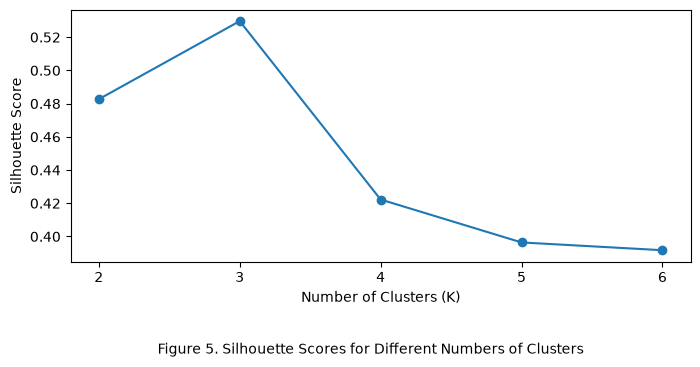

In [59]:
plt.figure(figsize=(8, 4))

plt.plot(range(2, 7), silhouette_scores, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 7))

plt.subplots_adjust(bottom=0.25)
plt.figtext(
    0.5, 0.02,
    "Figure 5. Silhouette Scores for Different Numbers of Clusters",
    ha="center"
)
plt.show()

The silhouette scores for K values from 2 to 6 are presented in Figure 5. The highest score was obtained with three clusters (0.530), followed by K = 2 (0.483). Increasing the number of clusters beyond three resulted in lower scores, reaching 0.392 at K = 6.
These results suggest that the three-cluster solution provides the most favourable balance between within-cluster cohesion and between-cluster separation among the configurations tested. Therefore, K = 3 was selected for the final clustering model. The characteristics of the resulting clusters were subsequently examined to assess their practical interpretation.

3.1.3 Final Clustering Results

Based on the silhouette analysis, K = 3 was selected for the final clustering model. The K-means pipeline was fitted using all four standardised features, and each of the 392 monitoring series was assigned to one of three clusters.
The resulting cluster sizes and feature characteristics were examined to understand how the groups differed in their historical water-level behaviour.

In [71]:
# Fit the final K-means model with K = 3
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=20,
        random_state=0
    ))
])
cluster_labels = final_model.fit_predict(X_cluster)
# Add cluster assignments to the feature dataset
cluster_results = clustering_features.copy()
cluster_results["Cluster"] = cluster_labels

In [75]:

# Count the monitoring records in each cluster
cluster_sizes = cluster_results["Cluster"].value_counts().sort_index()

# Calculate the mean feature values for each cluster
cluster_summary = cluster_results.groupby("Cluster")[
    ["IQR", "Daily_Change", "Seasonal_Difference", "Within_Day_Range"]
].mean()

# Combine cluster sizes and mean feature values
cluster_table = cluster_summary.round(3).copy()
cluster_table.insert(0, "Records", cluster_sizes)

display(cluster_table)

,Records,IQR,Daily_Change,Seasonal_Difference,Within_Day_Range
Cluster,,,,,
0,272,0.201,0.022,0.173,0.046
1,98,0.470,0.051,0.430,0.125
2,22,0.292,0.103,0.094,2.824


3.6 Cluster Visualisation

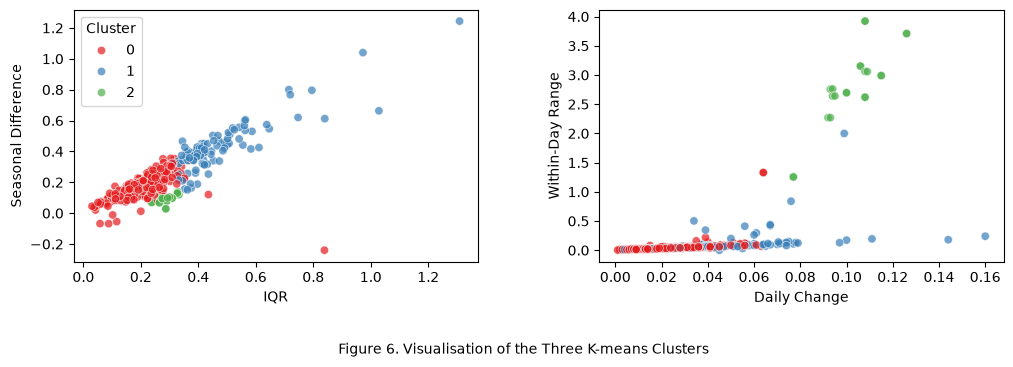

In [76]:

# Visualise the final K-means clusters
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Overall and seasonal variation
sns.scatterplot(
    data=cluster_results,
    x="IQR",
    y="Seasonal_Difference",
    hue="Cluster",
    palette="Set1",
    alpha=0.7,
    ax=axes[0]
)

axes[0].set_xlabel("IQR")
axes[0].set_ylabel("Seasonal Difference")

# Plot 2: Daily and within-day variation
sns.scatterplot(
    data=cluster_results,
    x="Daily_Change",
    y="Within_Day_Range",
    hue="Cluster",
    palette="Set1",
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_xlabel("Daily Change")
axes[1].set_ylabel("Within-Day Range")
axes[1].get_legend().remove()

# Figure caption
plt.subplots_adjust(bottom=0.25, wspace=0.3)
plt.figtext(
    0.5, 0.02,
    "Figure 6. Visualisation of the Three K-means Clusters",
    ha="center"
)

plt.show()

Figure 6 illustrates the distribution of the three clusters across the four selected features. In the left panel, Cluster 0 is mainly concentrated at lower IQR and seasonal difference values, while Cluster 1 generally extends towards higher values of both features. However, some overlap is observed between the clusters.
The right panel shows a clearer distinction, particularly for Cluster 2. Most records in this cluster have substantially higher within-day ranges than those in Clusters 0 and 1, despite some overlap in daily change. This is consistent with the feature summaries in Table 1, where Cluster 2 has a mean within-day range of 2.824, compared with 0.046 and 0.125 for Clusters 0 and 1, respectively.
These visualisations illustrate differences in water-level behaviour across the three clusters. However, as each plot displays only two of the four features used by K-means, they provide a partial representation of the clustering results.

The final K-means model was fitted using K = 3, assigning all 392 monitoring series to three clusters. As shown in Table 1, Cluster 0 was the largest group, containing 272 records (69.4%), followed by Cluster 1 with 98 records (25.0%) and Cluster 2 with 22 records (5.6%).

The cluster-level feature summaries revealed clear differences between the groups. Cluster 0 had the lowest IQR (0.201), daily change (0.022) and within-day range (0.046). Cluster 1 showed the highest IQR (0.470) and winter–summer difference (0.430), whereas Cluster 2 had the highest daily change (0.103) and a substantially larger within-day range (2.824) than the other two clusters.

These results demonstrate that the model identified groups with distinct combinations of water-level characteristics. Their hydrological significance is examined further in the interpretation and discussion section.

3.2 Regression

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

In [63]:
# Add cluster labels to the monitoring station information
station_clusters = df_avg[
    ["Station_Name", "Observation_ID"]
].copy()

station_clusters["Cluster"] = cluster_labels

# Display monitoring records in Cluster 2
display(
    station_clusters[station_clusters["Cluster"] == 2]
)

,Station_Name,Observation_ID,Cluster
40,Portrush,argyll-and-bute__portrush-argyll-and-bute-tida...,2
41,Portrush,argyll-and-bute__portrush-argyll-and-bute__obs1,2
43,Tobermory,argyll-and-bute__tobermory-argyll-and-bute-tid...,2
44,Tobermory,argyll-and-bute__tobermory-argyll-and-bute__obs1,2
65,Millport,ayrshire-and-arran__millport-ayrshire-and-arra...,2
66,Millport,ayrshire-and-arran__millport-ayrshire-and-arra...,2
86,Wick,caithness__wick-caithness-tidal-level__obs2,2
87,Wick,caithness__wick-caithness__obs1,2
89,Aberdeen,city-of-aberdeen__aberdeen-city-of-aberdeen-ti...,2
90,Aberdeen,city-of-aberdeen__aberdeen-city-of-aberdeen__obs2,2


# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [74]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] WARNING | pattern 'project.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execute
    Exe